# Structural Bioinformatics Analysis of the p53 DNA-Binding Domain

## 1. Environment & Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Structural Bioinformatics & 3D Visualization
import Bio
from Bio.PDB import PDBList, PDBParser, PPBuilder
import py3Dmol

# Plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 300

print(f"BioPython version: {Bio.__version__}")
print("Structural bioinformatics stack successfully loaded!")

BioPython version: 1.88
Structural bioinformatics stack successfully loaded!


## 2. Automated PDB Structure Retrieval & Sequence Extraction

In [2]:
# 1. Download p53 PDB Structure (1TUP)
pdb_id = "1tup"
pdbl = PDBList()
pdb_file = pdbl.retrieve_pdb_file(pdb_id, pdir='.', file_format='pdb')

# 2. Parse PDB Structure Architecture
parser = PDBParser(QUIET=True)
structure = parser.get_structure('p53', pdb_file)

# 3. Extract Amino Acid Sequence from Structure Chains
ppb = PPBuilder()
sequences = []

for model in structure:
    for chain in model:
        for pp in ppb.build_peptides(chain):
            seq = pp.get_sequence()
            sequences.append({
                'Chain': chain.id,
                'Length': len(seq),
                'Sequence': str(seq)
            })

df_seq = pd.DataFrame(sequences)
print(f"Successfully loaded PDB: {pdb_id.upper()}")
print("\nExtracted Protein Chains & Primary Sequences:")
df_seq

Structure exists: '.\pdb1tup.ent' 
Successfully loaded PDB: 1TUP

Extracted Protein Chains & Primary Sequences:


,Chain,Length,Sequence
0,A,196,SSSVPSQKTYQGSYGFRLGFLHSGTAKSVTCTYSPALNKMFCQLAK...
1,B,194,SVPSQKTYQGSYGFRLGFLHSGTAKSVTCTYSPALNKMFCQLAKTC...
2,C,195,SSVPSQKTYQGSYGFRLGFLHSGTAKSVTCTYSPALNKMFCQLAKT...


## 3. Interactive 3D Structural Visualization

In [3]:
# 1. Read local PDB file contents
with open(pdb_file, 'r') as f:
    pdb_data = f.read()

# 2. Initialize 3D Viewer canvas
view = py3Dmol.view(width=800, height=500)
view.addModel(pdb_data, 'pdb')

# 3. Apply Cartoon Style & Secondary Structure Coloring
# (Alpha helices = purple/magenta, Beta sheets = yellow/orange, Coils = cyan)
view.setStyle({'cartoon': {'color': 'spectrum'}})

# 4. Highlight key chain domains / active sites
view.setBackgroundColor('#1E1E1E')  # Dark sleek background for contrast
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 4. Spatial Contact Map & Residue Distance Matrix

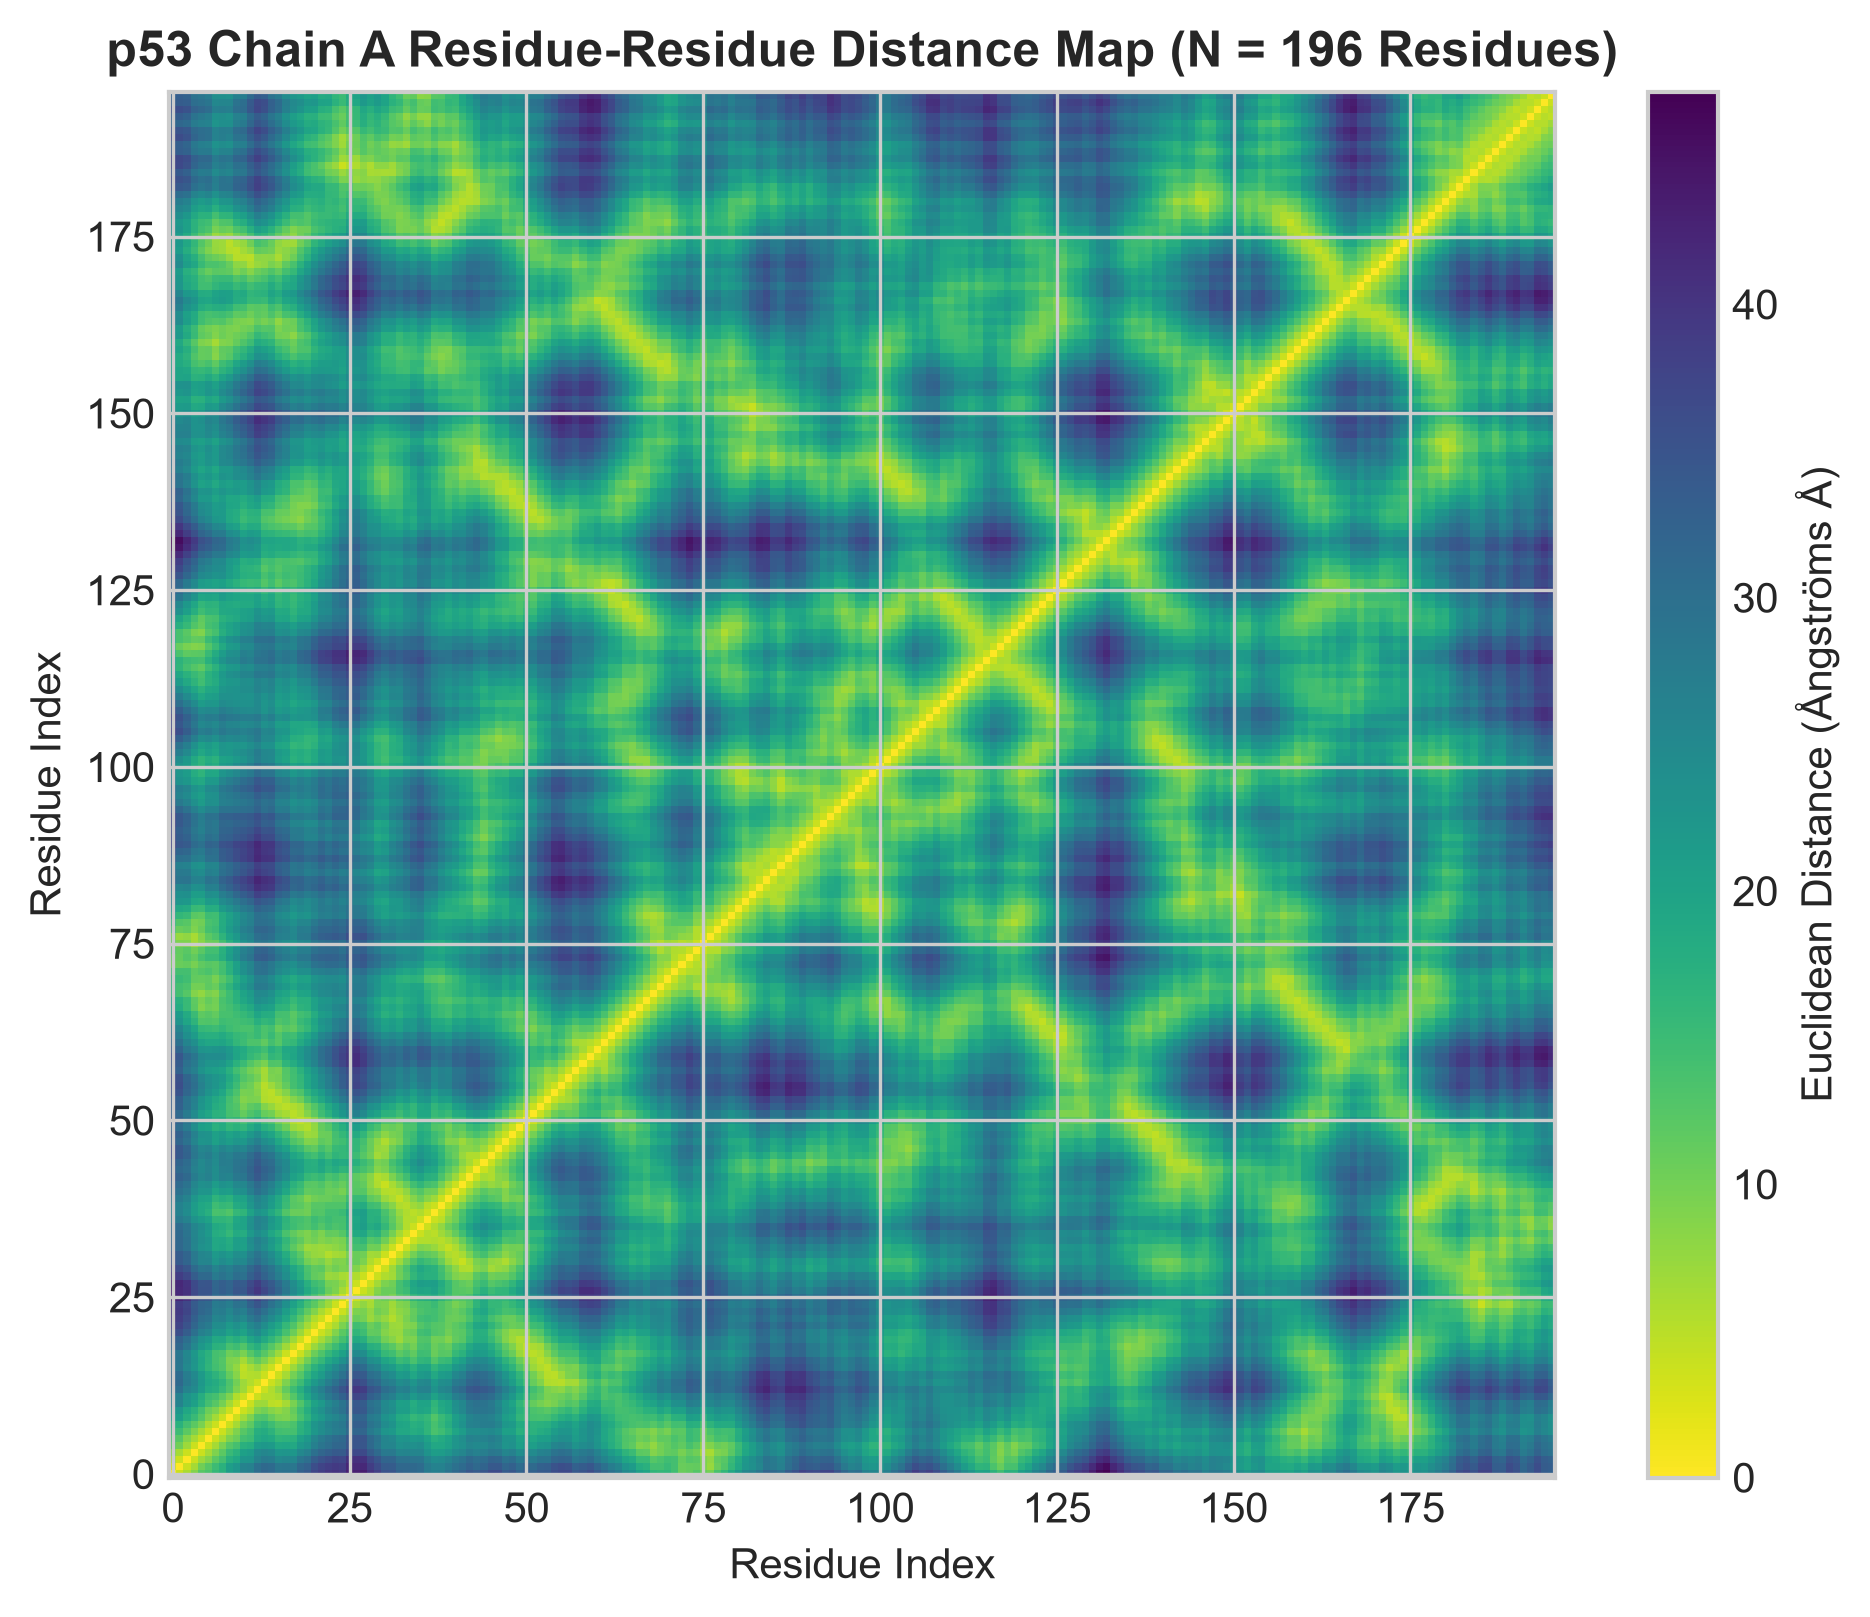

Extracted 196 Alpha-Carbon coordinates.
Distance matrix successfully saved as 'p53_distance_matrix.png'!


In [4]:
# 1. Extract Alpha Carbon (CA) 3D coordinates for Chain A
chain_a = structure[0]['A']
ca_atoms = [atom for atom in chain_a.get_atoms() if atom.get_name() == 'CA']
coords = np.array([atom.get_coord() for atom in ca_atoms])

# 2. Compute Pairwise Euclidean Distance Matrix (Residue vs Residue)
# Distance equation: d = sqrt((x2-x1)^2 + (y2-y1)^2 + (z2-z1)^2)
num_residues = len(coords)
dist_matrix = np.zeros((num_residues, num_residues))

for i in range(num_residues):
    for j in range(num_residues):
        dist_matrix[i, j] = np.linalg.norm(coords[i] - coords[j])

# 3. Plot Spatial Contact Heatmap
plt.figure(figsize=(8, 6))
plt.imshow(dist_matrix, cmap='viridis_r', origin='lower')
plt.colorbar(label='Euclidean Distance (Ångströms Å)')
plt.title(f'p53 Chain A Residue-Residue Distance Map (N = {num_residues} Residues)', fontsize=12, fontweight='bold')
plt.xlabel('Residue Index')
plt.ylabel('Residue Index')
plt.savefig("p53_distance_matrix.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Extracted {num_residues} Alpha-Carbon coordinates.")
print("Distance matrix successfully saved as 'p53_distance_matrix.png'!")

### How to Read the Residue-Distance Matrix

The distance matrix represents pairwise Euclidean distances between the Cα atoms of 196 residues in chain A of the p53 DNA-binding domain.

- **Main diagonal:** Each residue is compared with itself, producing a distance of 0 Å. Consecutive residues generally have Cα–Cα distances of approximately 3.8 Å.
- **Low-distance regions away from the diagonal:** These indicate residues that are separated in the amino acid sequence but relatively close together in three-dimensional space.
- **High-distance regions:** These represent residue pairs that are farther apart in the observed structure.

The figure is a continuous residue-distance map rather than a binary contact map. Spatial contacts can be defined by applying a distance threshold.

### Structural Interpretation

The distance matrix reveals spatial relationships within the experimentally determined p53 DNA-binding domain. Low-distance regions away from the main diagonal may reflect interactions between nonadjacent sequence regions, including tertiary contacts that contribute to the domain's folded architecture.

However, the distance map alone does not establish specific DNA-binding interactions, protein stability, or functional mechanisms. Those interpretations require additional structural or experimental evidence.

## 5. Amino Acid Biophysical Feature Profiling

p53 Chain A Length: 196 aa
Molecular Weight: 22.00 kDa
Theoretical Isoelectric Point (pI): 8.34


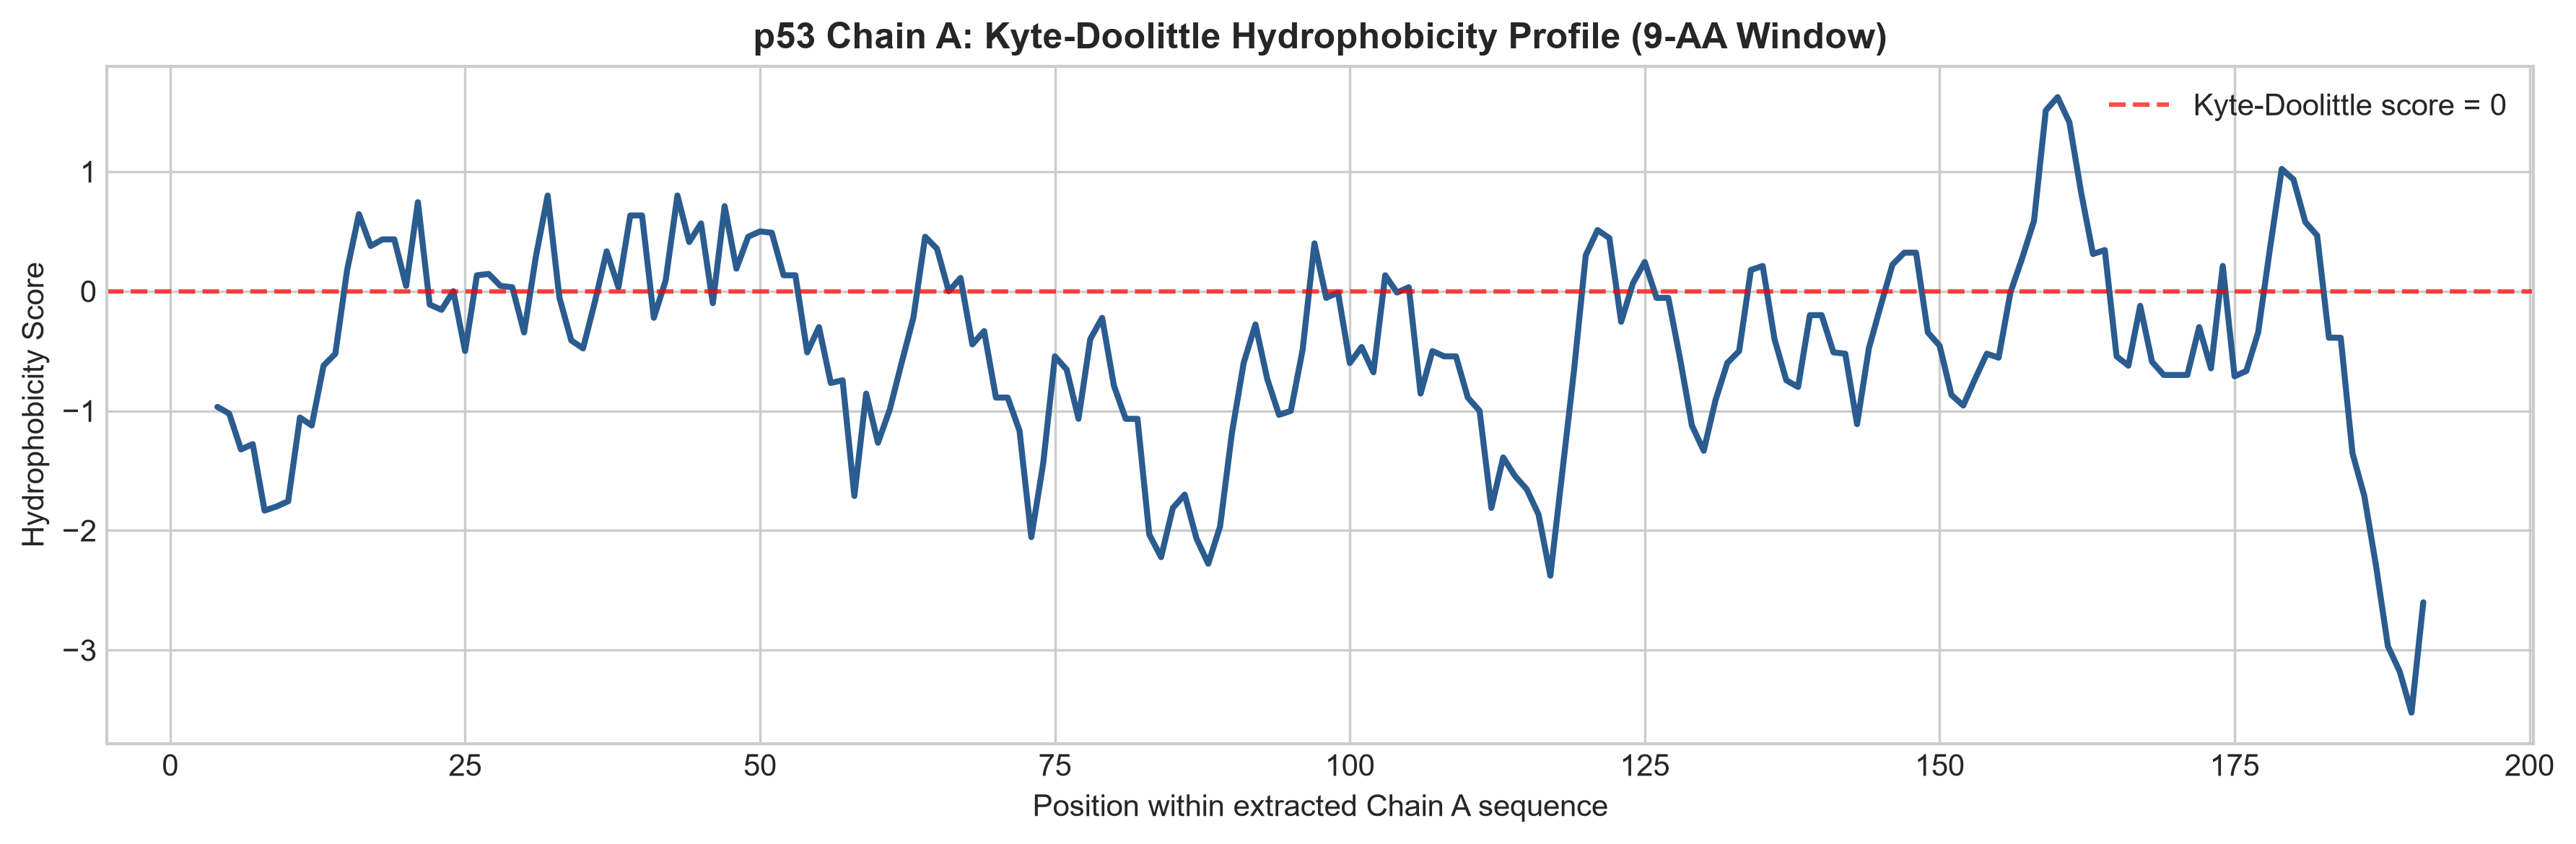

In [5]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis

# 1. Extract pure amino acid sequence string from Chain A
p53_seq_str = df_seq[df_seq['Chain'] == 'A']['Sequence'].values[0]
analysed_seq = ProteinAnalysis(p53_seq_str)

# 2. Compute Global Biophysical Properties
mol_wt = analysed_seq.molecular_weight()
isoelectric_pt = analysed_seq.isoelectric_point()
amino_counts = analysed_seq.count_amino_acids()

print(f"p53 Chain A Length: {len(p53_seq_str)} aa")
print(f"Molecular Weight: {mol_wt/1000:.2f} kDa")
print(f"Theoretical Isoelectric Point (pI): {isoelectric_pt:.2f}")

# 3. Rolling Kyte-Doolittle Hydrophobicity Profile
kd_scale = {
    'A': 1.8, 'R': -4.5, 'N': -3.5, 'D': -3.5, 'C': 2.5,
    'Q': -3.5, 'E': -3.5, 'G': -0.4, 'H': -3.2, 'I': 4.5,
    'L': 3.8, 'K': -3.9, 'M': 1.9, 'F': 2.8, 'P': -1.6,
    'S': -0.8, 'T': -0.7, 'W': -0.9, 'Y': -1.3, 'V': 4.2
}

window_size = 9
hydrophobicity = [
    np.mean([kd_scale.get(aa, 0) for aa in p53_seq_str[i:i+window_size]])
    for i in range(len(p53_seq_str) - window_size + 1)
]

# 4. Plot Hydrophobicity Profile Across Sequence
plt.figure(figsize=(12, 4))
plt.plot(range(window_size//2, len(hydrophobicity) + window_size//2), hydrophobicity, color='#2b5c8f', linewidth=2)
plt.axhline(
    0,
    color='red',
    linestyle='--',
    alpha=0.7,
    label='Kyte-Doolittle score = 0'
)
plt.title('p53 Chain A: Kyte-Doolittle Hydrophobicity Profile (9-AA Window)', fontsize=12, fontweight='bold')
plt.xlabel('Position within extracted Chain A sequence')
plt.ylabel('Hydrophobicity Score')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig("p53_hydrophobicity_profile.png", dpi=300, bbox_inches='tight')
plt.show()

### Interpretation of Biophysical Properties

The extracted p53 chain A sequence contains 196 amino acids, with an estimated molecular weight of 22.00 kDa and a theoretical isoelectric point of 8.34. These values describe the extracted DNA-binding domain rather than full-length p53.

The nine-residue Kyte–Doolittle profile identifies regions with relatively higher or lower average hydrophobicity. Positive scores indicate greater hydrophobic character, while negative scores indicate more hydrophilic character.

Although hydrophobicity can influence protein folding and molecular interactions, this sequence-based profile does not directly identify buried residues or solvent-accessible surfaces. Structural accessibility would require an additional analysis of the three-dimensional coordinates.

## 6. Residue Contact Density & Spatial Coordination Analysis

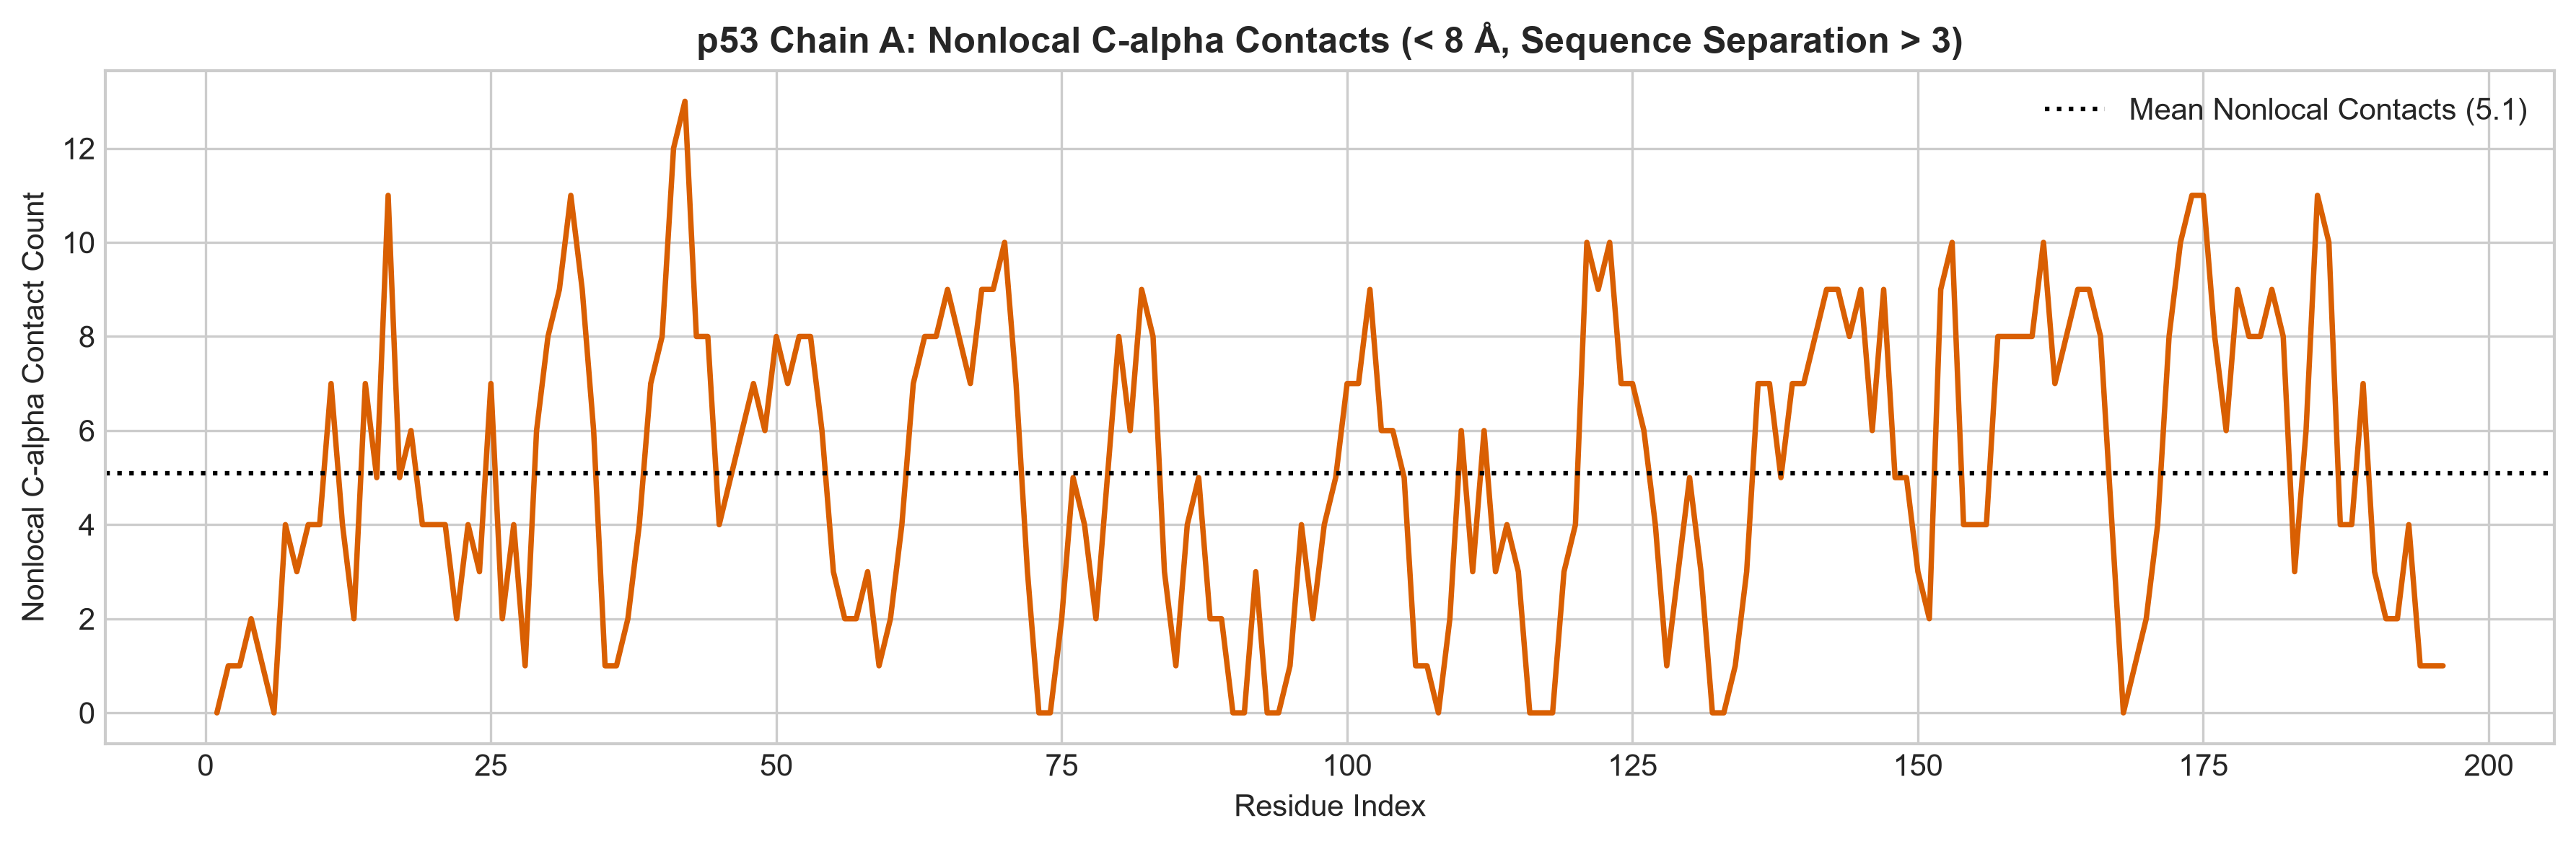

Average nonlocal contacts per residue: 5.09
Highest nonlocal contact count: Residue index 42 (13 contacts)


In [6]:
# Define spatial contact threshold (8.0 Ångströms is standard for alpha-carbon packing)
contact_cutoff = 8.0  # Å

# Define sequence separation between residue pairs
residue_indices = np.arange(num_residues)

sequence_separation = np.abs(
    residue_indices[:, None] - residue_indices[None, :]
)

# Count nonlocal C-alpha contacts within 8 Angstroms
contact_matrix = (
    (dist_matrix < contact_cutoff)
    & (sequence_separation > 3)
)

coordination_numbers = np.sum(contact_matrix, axis=1)

# 4. Plot Coordination Number distribution across p53 sequence
plt.figure(figsize=(12, 4))
plt.plot(range(1, len(coordination_numbers) + 1), coordination_numbers, color='#d95f02', linewidth=1.8)
plt.axhline(
    np.mean(coordination_numbers),
    color='black',
    linestyle=':',
    label=f'Mean Nonlocal Contacts ({np.mean(coordination_numbers):.1f})'
)

plt.title(
    'p53 Chain A: Nonlocal C-alpha Contacts (< 8 Å, Sequence Separation > 3)',
    fontsize=12,
    fontweight='bold'
)
plt.xlabel('Residue Index')
plt.ylabel('Nonlocal C-alpha Contact Count')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig("p53_coordination_profile.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Average nonlocal contacts per residue: {np.mean(coordination_numbers):.2f}")
print(
    f"Highest nonlocal contact count: "
    f"Residue index {np.argmax(coordination_numbers) + 1} "
    f"({np.max(coordination_numbers)} contacts)"
)

### Interpretation of Nonlocal Spatial Contacts

The coordination analysis counts Cα atoms within 8 Å of each residue while excluding residue pairs separated by three or fewer positions in the amino acid sequence.

This restriction reduces the influence of immediate sequence neighbors and provides a more focused measure of nonlocal residue contacts.

Higher contact counts indicate residues with more neighboring Cα atoms under the selected criteria. Lower counts indicate fewer such contacts. These differences may reflect aspects of local packing and tertiary structure, but they do not independently establish solvent accessibility, structural flexibility, or biological function.

The results depend on the selected distance threshold and sequence-separation criterion.

## 7. Secondary Structure Composition & Architectural Summary

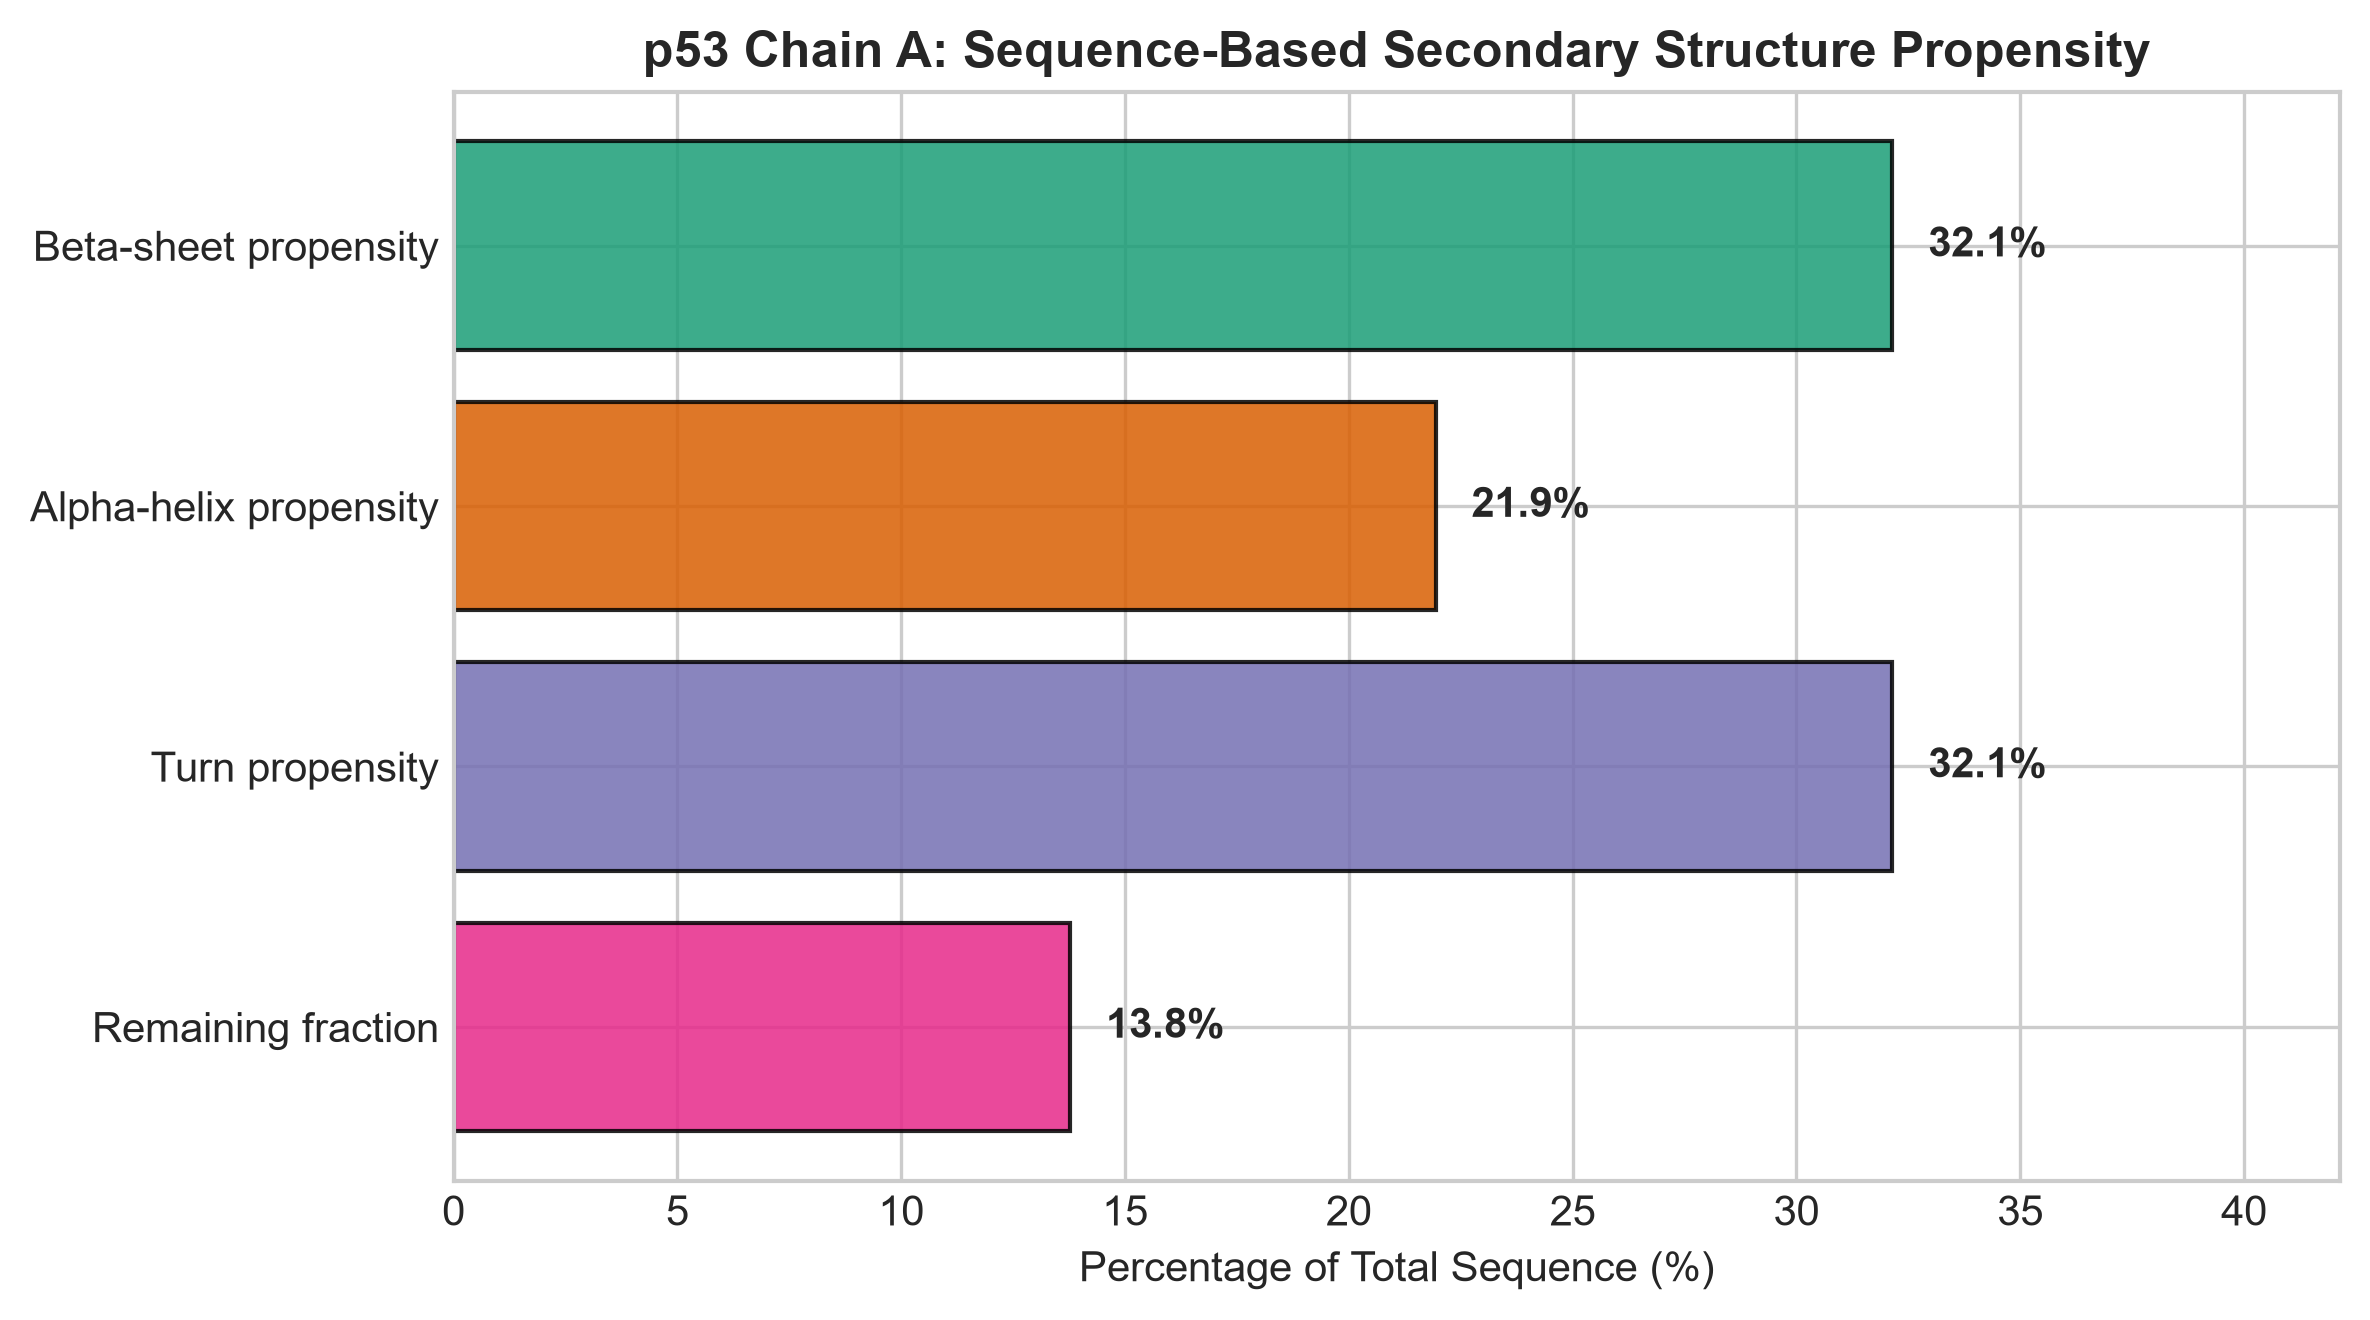


--- Structural Pipeline Execution Summary ---
Total Residues Analyzed: 196
Predominant Secondary Motif: Beta-sheet propensity (32.1%)
All figures successfully exported to working directory!


In [7]:
# 1. Calculate Secondary Structure Fraction (Helix, Turn, Sheet)
helix_frac, turn_frac, sheet_frac = analysed_seq.secondary_structure_fraction()
coil_frac = 1.0 - (helix_frac + turn_frac + sheet_frac)

sec_struct_data = {
    'Motif': [
        'Beta-sheet propensity',
        'Alpha-helix propensity',
        'Turn propensity',
        'Remaining fraction'
    ],
    'Percentage': [
        sheet_frac * 100,
        helix_frac * 100,
        turn_frac * 100,
        coil_frac * 100
    ]
}
df_sec = pd.DataFrame(sec_struct_data)

# 2. Plot Secondary Structure Breakdown
plt.figure(figsize=(8, 4.5))
colors = ['#1b9e77', '#d95f02', '#7570b3', '#e7298a']
bars = plt.barh(df_sec['Motif'], df_sec['Percentage'], color=colors, edgecolor='black', alpha=0.85)

# Add text labels on bars
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.8, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', 
             va='center', ha='left', fontweight='bold', fontsize=10)

plt.title(
    'p53 Chain A: Sequence-Based Secondary Structure Propensity',
    fontsize=12,
    fontweight='bold'
)
plt.xlabel('Percentage of Total Sequence (%)')
plt.xlim(0, max(df_sec['Percentage']) + 10)
plt.gca().invert_yaxis()  # Top-down order
plt.tight_layout()
plt.savefig("p53_secondary_structure_composition.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n--- Structural Pipeline Execution Summary ---")
print(f"Total Residues Analyzed: {len(p53_seq_str)}")
print(f"Predominant Secondary Motif: {df_sec.iloc[df_sec['Percentage'].idxmax()]['Motif']} ({df_sec['Percentage'].max():.1f}%)")
print("All figures successfully exported to working directory!")

### Interpretation of Secondary-Structure Propensity

Biopython's `ProteinAnalysis.secondary_structure_fraction()` provides sequence-based estimates of helix, turn, and sheet propensity using amino acid composition.

For the extracted p53 chain A sequence, the calculated values were approximately 32.1% beta-sheet propensity, 21.9% alpha-helix propensity, and 32.1% turn propensity. The remaining 13.8% represents the portion not included in these three estimated categories.

These results should not be interpreted as experimentally determined secondary-structure assignments. Although the p53 DNA-binding domain is known to contain a beta-sandwich architecture, confirming its secondary-structure composition from PDB coordinates would require a structure-based assignment method such as DSSP.

The sequence-based estimates are therefore useful for exploratory characterization but do not independently validate the observed three-dimensional architecture.

## Conclusions and Key Takeaways

This project applied structural bioinformatics methods to the experimentally determined p53 DNA-binding domain from PDB entry `1TUP`. The analysis combined protein structure retrieval, amino acid sequence extraction, spatial distance calculations, and sequence-based biophysical characterization.

### Key Findings

**1. Structural data retrieval and visualization**

The PDB structure was successfully retrieved and parsed using Biopython. Three p53 protein chains were identified, and chain A was selected for the subsequent structural calculations. The extracted chain A sequence contained 196 amino acids.

**2. Residue-distance analysis**

Pairwise Euclidean distances were calculated using Cα coordinates from chain A, producing a 196 × 196 distance matrix. The resulting visualization illustrates spatial relationships between residues, including regions that are distant in sequence but relatively close in three-dimensional space.

**3. Biophysical sequence characterization**

The extracted sequence had an estimated molecular weight of 22.00 kDa and a theoretical isoelectric point of 8.34. A nine-residue Kyte–Doolittle profile identified variation in hydrophobicity along the sequence. These measurements describe sequence-derived properties but do not independently establish residue burial or solvent accessibility.

**4. Nonlocal spatial contacts**

An 8 Å Cα distance threshold was used to quantify spatial contacts between residues separated by more than three positions in the sequence. This analysis provides a measure of nonlocal contact density and highlights differences in spatial packing across the extracted domain.

**5. Secondary-structure propensity**

Sequence-based estimates indicated approximately 32.1% beta-sheet propensity, 21.9% alpha-helix propensity, and 32.1% turn propensity. These values reflect amino acid composition rather than experimentally assigned secondary structures.

### Limitations

The structural calculations focused on a single p53 chain from one experimentally determined PDB entry. Results may differ across alternative structures, conformations, and experimental conditions.

The contact analysis depends on the chosen distance and sequence-separation thresholds. Hydrophobicity and secondary-structure propensity were calculated from the amino acid sequence and should not be interpreted as direct measurements of solvent accessibility or observed secondary-structure composition.

### Overall Conclusion

The project demonstrates how Python and Biopython can be used to retrieve and characterize protein structural data, translate atomic coordinates into quantitative spatial measurements, and visualize sequence and structural properties.

An important distinction is that the workflow analyzes an existing experimentally determined structure rather than predicting a new protein fold. It provides an exploratory foundation for more advanced structural bioinformatics analyses, including structure-based secondary-structure assignment, solvent-accessibility calculations, and comparisons across protein variants.